# Tugas Praktikum JS06 Regresi - Dataset PBL
## Analisis Regresi Linier dan Regularisasi pada Fitur Berita PBL


### 1. Load dataset PBL


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('data/pbl_hoaks_valid_clean.csv')
print('Dimensi data:', df.shape)
df.head()


Dimensi data: (1498, 2)


,teks_bersih,label
0,presiden prabowo minta maaf ikut bop akan kemb...,1
1,video presiden prabowo akan membagikan bantuan...,1
2,pemerintah kota tangerang selatan akan legalka...,1
3,tautan rekrutmen cpns kementerian imigrasi,1
4,ramuan rebusan jahe kunyit kencur dan serai be...,1


### 2. Ekstraksi fitur statistik teks (panjang karakter, jumlah kata, rasio unik)


In [2]:
df['char_count'] = df['teks_bersih'].apply(len)
df['word_count'] = df['teks_bersih'].apply(lambda x: len(x.split()))
df['unique_word_ratio'] = df['teks_bersih'].apply(lambda x: len(set(x.split())) / (len(x.split()) + 1e-5))
df['avg_word_length'] = df['char_count'] / (df['word_count'] + 1e-5)

print(df[['char_count', 'word_count', 'unique_word_ratio', 'avg_word_length', 'label']].describe())


        char_count   word_count  unique_word_ratio  avg_word_length  \
count  1498.000000  1498.000000        1498.000000      1498.000000   
mean    145.069426    20.662884           0.879829         7.045712   
std      70.235869     9.954766           0.114664         0.739366   
min      20.000000     4.000000           0.472222         4.714279   
25%      64.250000     9.000000           0.794306         6.576047   
50%     167.000000    24.000000           0.888889         6.999998   
75%     199.000000    28.000000           0.999998         7.499991   
max     489.000000    75.000000           1.000000        10.571413   

             label  
count  1498.000000  
mean      0.500000  
std       0.500167  
min       0.000000  
25%       0.000000  
50%       0.500000  
75%       1.000000  
max       1.000000  


### 3. Matriks korelasi antar variabel statistik teks


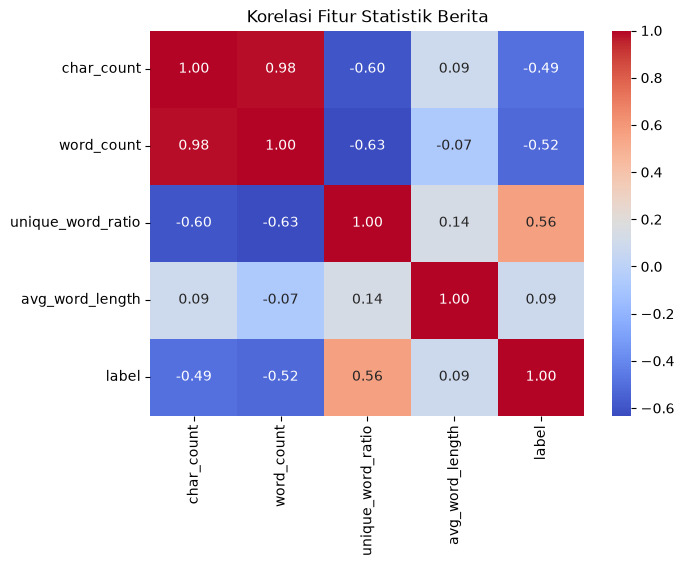

In [3]:
plt.figure(figsize=(7, 5))
sns.heatmap(df[['char_count', 'word_count', 'unique_word_ratio', 'avg_word_length', 'label']].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Korelasi Fitur Statistik Berita')
plt.show()


### 4. Pemodelan Regresi Linier Berganda (Linear Regression)


In [4]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

# Prediksi char_count berdasarkan word_count, unique_word_ratio, avg_word_length, dan label
features = ['word_count', 'unique_word_ratio', 'avg_word_length', 'label']
X = df[features]
y = df['char_count']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)

print('Koefisien Regresi:', dict(zip(features, lr.coef_)))
print('Intercept        :', lr.intercept_)
print(f'R2 Score         : {r2_score(y_test, y_pred_lr):.4f}')
print(f'MSE              : {mean_squared_error(y_test, y_pred_lr):.4f}')
print(f'RMSE             : {np.sqrt(mean_squared_error(y_test, y_pred_lr)):.4f}')
print(f'MAE              : {mean_absolute_error(y_test, y_pred_lr):.4f}')


Koefisien Regresi: {'word_count': np.float64(7.0742105841114125), 'unique_word_ratio': np.float64(5.358715180570424), 'avg_word_length': np.float64(15.239681656747223), 'label': np.float64(0.6972989836175056)}
Intercept        : -113.6502571696164
R2 Score         : 0.9894
MSE              : 51.7910
RMSE             : 7.1966
MAE              : 5.3541


### 5. Plot Aktual vs Prediksi Regresi Linier


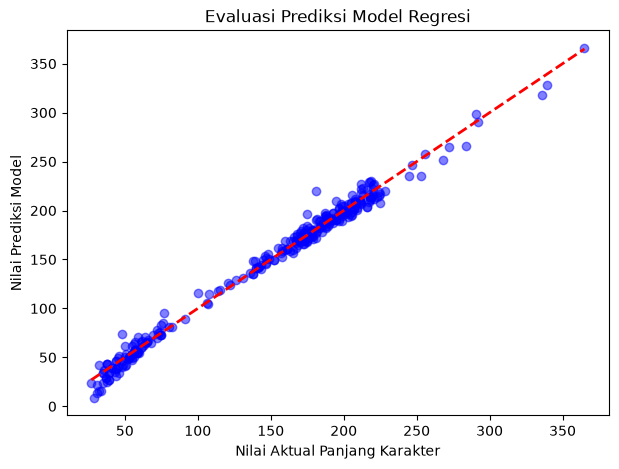

In [5]:
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred_lr, alpha=0.5, color='blue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], '--r', lw=2)
plt.xlabel('Nilai Aktual Panjang Karakter')
plt.ylabel('Nilai Prediksi Model')
plt.title('Evaluasi Prediksi Model Regresi')
plt.show()
